# Stochastic series - AR(1) generator

This tutorial shows the `plans.stochastic` functions that make and fit synthetic series. They work on plain `numpy` arrays and a `period` (steps per cycle), so there are no dates and no units involved.

A series is a linear trend, a seasonal term and a remainder with memory:

$$x_t = \underbrace{b + a\,t}_{\text{trend}} + \underbrace{A\,(g_t - m_k)}_{\text{season}} + R_t, \qquad R_t = \varphi R_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

The season $g_t$ is a raised cosine to a power $k$, and $m_k$ is its average over a cycle.

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans import viewer
from plans.stochastic import (
    make_params,
    build,
    fit_params,
    decompose,
    describe,
    get_floor,
    season_shape,
)

# Same style and figure sizes of the plans figures
viewer.set_style(style="wien")
plt.rcParams["figure.dpi"] = viewer.FIG_DPI
plt.rcParams["axes.titlelocation"] = "left"


def inches(size):
    return viewer.FIG_SIZES[size]["w"] / 25.4, viewer.FIG_SIZES[size]["h"] / 25.4


GRAY, BLUE, ORANGE, RED = "gray", "blue", "orange", "red"
LEGEND = {"loc": "upper left", "bbox_to_anchor": (1, 1)}

## Make the parameters

`make_params()` takes what you know and converts it to a small dictionary of numbers. Here is a temperature-like monthly series over 20 years, given by its average, its change per cycle and its coldest and warmest points. The season peaks at step 6 of each cycle:

In [2]:
n = 240
truth = make_params(
    period=12,
    average=15,
    n=n,
    cycle_change=0.1,
    baseline=10,
    topline=20,
    phase=6,
    phi=0.5,
    sigma=1,
)
truth

{'start': 14.004166666666666,
 'slope': 0.008333333333333333,
 'amplitude': 10.0,
 'period': 12,
 'phase': 6.0,
 'power': 1.0,
 'phi': 0.5,
 'sigma': 1.0}

`describe()` prints every view of the same model, so you can read it in the form you know:

In [3]:
print(describe(params=truth, n=n))

start                                14.0042
slope per step                    0.00833333
slope per cycle                          0.1
trend end (n=240)                    15.9958
trend average (n=240)                     15
amplitude                                 10
baseline (at trend average)               10
topline (at trend average)                20
period                                    12
phase                                      6
power                                      1
phi                                      0.5
sigma                                      1
floor (n=240)                        9.00417


## Build a series

`build()` makes a series from the parameters. The `seed` makes it reproducible:

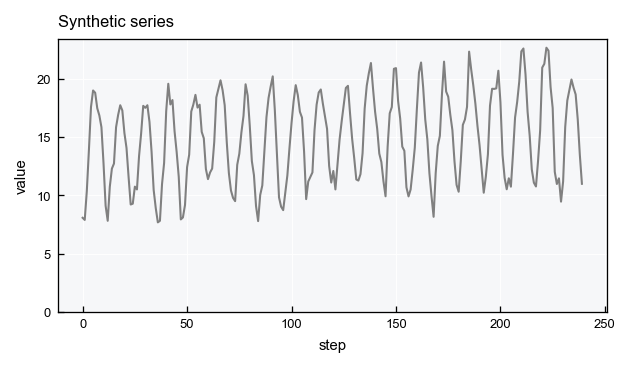

In [4]:
x = build(params=truth, n=n, seed=5)

fig, ax = plt.subplots(figsize=inches("M2"))
ax.plot(x, color=GRAY)
ax.set(title="Synthetic series", xlabel="step", ylabel="value", ylim=(0, None))
plt.show()

## Fit the parameters

`fit_params()` goes the other way, from data to parameters. The series was made from known values, so we can compare them. Only `period` is an input, because it is never estimated:

In [5]:
fit = fit_params(x=x, period=12)

for key in ["start", "slope", "amplitude", "phase", "power", "phi", "sigma"]:
    print(f"{key:<10} true {truth[key]:8.4f}   fit {fit[key]:8.4f}")

start      true  14.0042   fit  13.4739
slope      true   0.0083   fit   0.0121
amplitude  true  10.0000   fit   9.8947
phase      true   6.0000   fit   5.9786
power      true   1.0000   fit   1.0000
phi        true   0.5000   fit   0.4784
sigma      true   1.0000   fit   0.9771


A single series carries sampling error, and `phi` is usually the most affected. Repeating the fit over many seeds shows the spread for this series length:

In [6]:
phis = [fit_params(x=build(params=truth, n=n, seed=s), period=12)["phi"] for s in range(50)]

print(f"phi: true {truth['phi']:.3f}, fitted {np.mean(phis):.3f} +- {np.std(phis):.3f}")

phi: true 0.500, fitted 0.476 +- 0.057


## Decompose a series

`decompose()` splits the series into its components, given the parameters. The remainder keeps the memory, while the shocks are what is left after removing it:

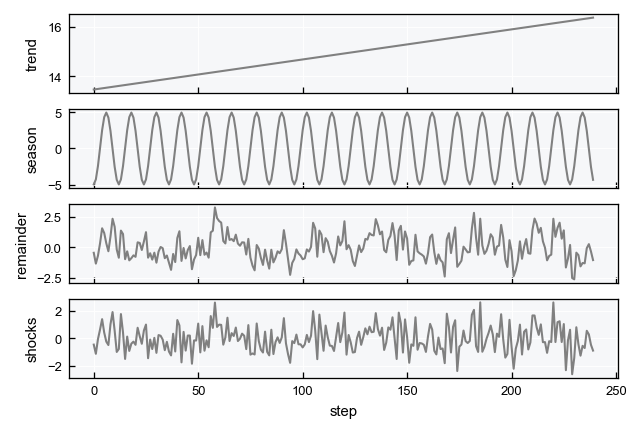

In [7]:
parts = decompose(x=x, params=fit)

fig, axes = plt.subplots(nrows=4, sharex=True, figsize=inches("M"))
for ax, name in zip(axes, ["trend", "season", "remainder", "shocks"]):
    ax.plot(parts[name], color=GRAY)
    ax.set_ylabel(name)
axes[-1].set_xlabel("step")
plt.show()

The shocks rebuild the original series exactly, so nothing is lost in the decomposition:

In [8]:
rebuilt = build(params=fit, n=n, shocks=parts["shocks"])
np.allclose(rebuilt, x)

True

## Autoregression

The memory is a relation between each step of the remainder and the step before it. Plotting one against the other shows it directly, and `phi` is the slope of the line through the origin:

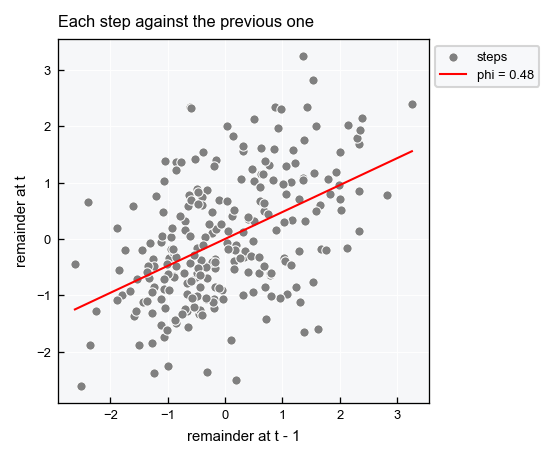

In [9]:
r = parts["remainder"]

fig, ax = plt.subplots(figsize=inches("S"))
ax.scatter(r[:-1], r[1:], s=20, color=GRAY, edgecolor="white", linewidth=0.5, label="steps")
line = np.array([r.min(), r.max()])
ax.plot(line, fit["phi"] * line, color=RED, label=f"phi = {fit['phi']:.2f}")
ax.set(title="Each step against the previous one", xlabel="remainder at t - 1", ylabel="remainder at t")
ax.legend(**LEGEND)
plt.show()

## Draw a new series

The same parameters with a new seed give a different series with the same behavior:

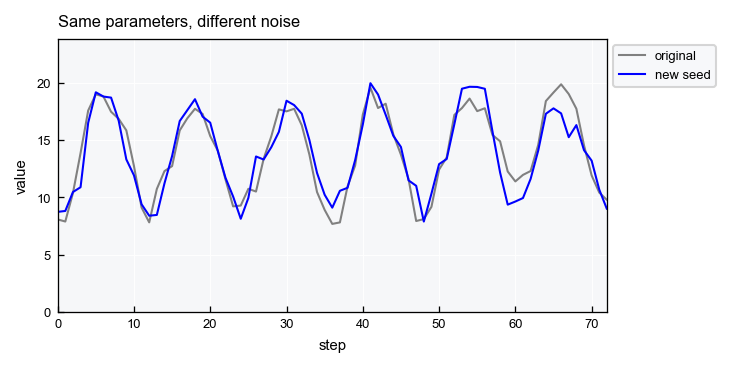

In [10]:
x_new = build(params=fit, n=n, seed=2)

fig, ax = plt.subplots(figsize=inches("M2"))
ax.plot(x, color=GRAY, label="original")
ax.plot(x_new, color=BLUE, label="new seed")
ax.set(title="Same parameters, different noise", xlabel="step", ylabel="value", xlim=(0, 72), ylim=(0, None))
ax.legend(**LEGEND)
plt.show()

## Change one parameter

To isolate the effect of a parameter, change it and build again with the same seed. Both series use the same random numbers, so the only difference is the parameter. A steeper trend adds a straight line to the same noise:

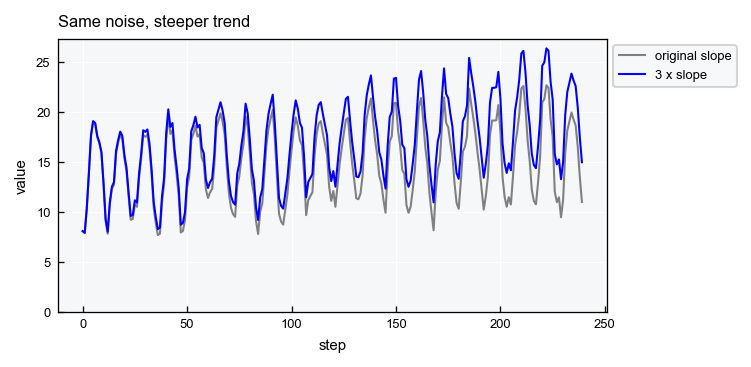

In [11]:
steeper = dict(truth, slope=3 * truth["slope"])

fig, ax = plt.subplots(figsize=inches("M2"))
ax.plot(build(params=truth, n=n, seed=5), color=GRAY, label="original slope")
ax.plot(build(params=steeper, n=n, seed=5), color=BLUE, label="3 x slope")
ax.set(title="Same noise, steeper trend", xlabel="step", ylabel="value", ylim=(0, None))
ax.legend(**LEGEND)
plt.show()

Memory is easier to see in the remainder. With a high `phi`, the remainder wanders away from zero and takes longer to return:

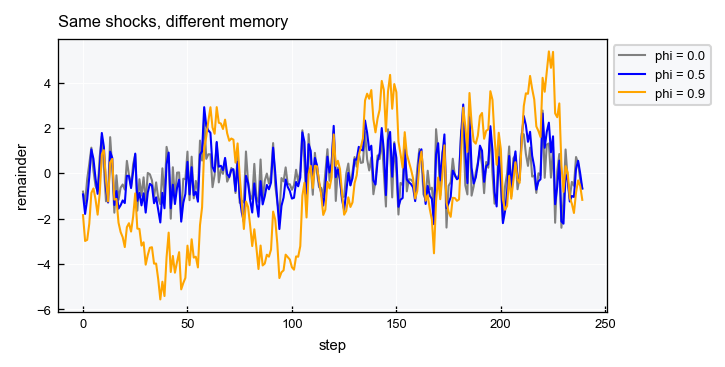

In [12]:
fig, ax = plt.subplots(figsize=inches("M2"))
for phi, color in [(0.0, GRAY), (0.5, BLUE), (0.9, ORANGE)]:
    params = dict(truth, phi=phi)
    y = build(params=params, n=n, seed=5)
    ax.plot(decompose(x=y, params=params)["remainder"], color=color, label=f"phi = {phi}")
ax.set(title="Same shocks, different memory", xlabel="step", ylabel="remainder")
ax.legend(**LEGEND)
plt.show()

## Shape of the season

`power` sets the shape of the season. A value of 1 is a plain cosine, and larger values give a sharper peak with a flat bottom:

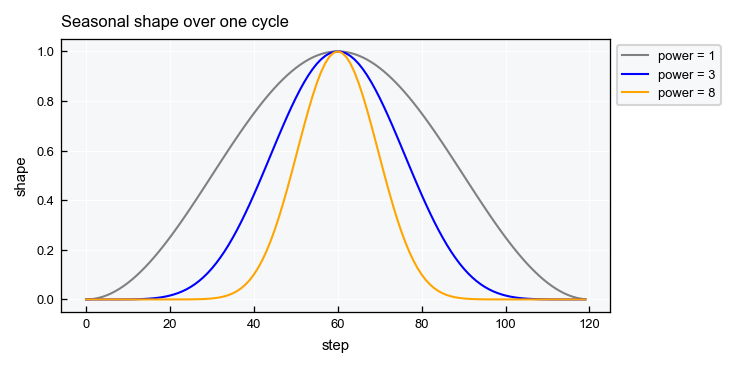

In [13]:
fig, ax = plt.subplots(figsize=inches("M2"))
for power, color in [(1, GRAY), (3, BLUE), (8, ORANGE)]:
    ax.plot(season_shape(n=120, period=120, phase=60, power=power), color=color, label=f"power = {power}")
ax.set(title="Seasonal shape over one cycle", xlabel="step", ylabel="shape")
ax.legend(**LEGEND)
plt.show()

## Limitation: positive variables

A sharp season looks like rainfall, and its trend plus season can stay above zero. The noise, however, is Gaussian and additive, so the series itself can still go below zero. Lets count those steps, and then prune them to zero:

lowest trend + season: 6.25
lowest value in series: -15.40
steps below zero: 11.7 %
mean before and after pruning: 99.39, 99.93


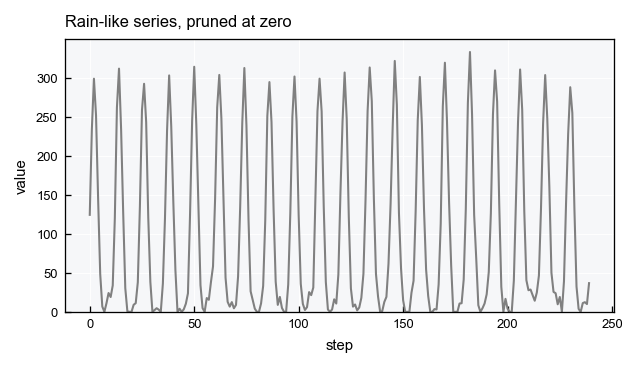

In [14]:
rain = make_params(period=12, start=100, amplitude=300, phase=2, power=3, phi=0.3, sigma=10)
y = build(params=rain, n=n, seed=5)
y_pruned = np.clip(y, a_min=0, a_max=None)

print(f"lowest trend + season: {get_floor(params=rain, n=n):.2f}")
print(f"lowest value in series: {y.min():.2f}")
print(f"steps below zero: {100 * np.mean(y < 0):.1f} %")
print(f"mean before and after pruning: {y.mean():.2f}, {y_pruned.mean():.2f}")

fig, ax = plt.subplots(figsize=inches("M2"))
ax.plot(y_pruned, color=GRAY)
ax.set(title="Rain-like series, pruned at zero", xlabel="step", ylabel="value", ylim=(0, None))
plt.show()

So this model suits variables like temperature better than rainfall or discharge. Pruning is a simple step to apply downstream, but it does not come from the model: it adds a small amount to the mean and piles values up at exactly zero.

## Recap

- `make_params()` converts what you know into parameters, and `describe()` shows all views of them.
- `build()` makes a series, and the same `seed` isolates the effect of changing one parameter.
- `fit_params()` estimates the parameters from a series without gaps, with at least 3 cycles of data.
- `decompose()` splits a series into trend, season, remainder and shocks.
- The noise is additive and Gaussian, so a variable that must stay positive can still go below zero and needs pruning downstream.